# Judge calibration: compare judge grades to human grades

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from agent.judge import judge
from agent.llm import LLM
from agent.schema import CRITERIA

GRADES_PATH = ROOT / "labeling" / "human_grades.csv"
TRAJ_DIR = ROOT / "labeling" / "trajectories"
RESULTS_DIR = ROOT / "labeling" / "judge_results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

grades = pd.read_csv(GRADES_PATH)
grades["traj_id"] = grades.case_id + "__" + grades.config
print(f"{len(grades)} human-graded trajectories across {grades.config.nunique()} config(s)")
grades[["traj_id", "request_id"] + list(CRITERIA)]

11 human-graded trajectories across 2 config(s)


,traj_id,request_id,grounded,sufficient_investigation,tool_use,efficiency,verdict_supported,remediation_quality
0,c01__nemotron-3-super-120b-a12b_think200_4r,8dfa15e9b4ba,pass,pass,fail,fail,pass,pass
1,c02__nemotron-3-super-120b-a12b_think200_4r,685ab5a81f78,pass,pass,pass,fail,pass,pass
2,c03__nemotron-3.5-lightning-30b-a3b_think200_8r,541dcac9b180,fail,fail,fail,fail,fail,pass
3,c05__nemotron-3-super-120b-a12b_think200_4r,4dee0e9b4251,fail,fail,fail,fail,fail,fail
4,c05__nemotron-3.5-lightning-30b-a3b_think200_8r,9d942818d7bf,pass,fail,fail,fail,fail,pass
5,c06__nemotron-3-super-120b-a12b_think200_4r,d1c72accca66,pass,fail,fail,fail,fail,pass
6,c06__nemotron-3.5-lightning-30b-a3b_think200_8r,aa080ecd3d9a,pass,pass,pass,fail,pass,pass
7,c07__nemotron-3-super-120b-a12b_think200_4r,65ec8c41914e,fail,fail,pass,fail,fail,pass
8,c10__nemotron-3-super-120b-a12b_think200_4r,ab8e5a8af3bd,fail,fail,fail,fail,fail,fail
9,c12__nemotron-3-super-120b-a12b_think200_4r,a247b0d36766,pass,pass,pass,fail,pass,fail


## Split: tune vs held-out
Edit TUNE to pick which trajectories go to tuning (by `traj_id` = `case_id__config`). Change USE to `"held_out"` for final validation.

In [2]:
TUNE = set([
    "c01__nemotron-3-super-120b-a12b_think200_4r",
    "c02__nemotron-3-super-120b-a12b_think200_4r",
    "c03__nemotron-3.5-lightning-30b-a3b_think200_8r",
    "c05__nemotron-3-super-120b-a12b_think200_4r",
    "c05__nemotron-3.5-lightning-30b-a3b_think200_8r",
    "c06__nemotron-3-super-120b-a12b_think200_4r",
    "c06__nemotron-3.5-lightning-30b-a3b_think200_8r"
])  # add traj_ids here, e.g. {"c01__nemotron-3-super-120b-a12b_think200_4r"}
USE = "tune"  # change to "held_out" for final validation

all_ids = set(grades.traj_id)
held_out = all_ids - TUNE
selected = TUNE if USE == "tune" else held_out
subset = grades[grades.traj_id.isin(selected)].copy()
print(f"using {USE}: {len(subset)} trajectories")
subset[["traj_id", "request_id"] + list(CRITERIA)]

using tune: 7 trajectories


,traj_id,request_id,grounded,sufficient_investigation,tool_use,efficiency,verdict_supported,remediation_quality
0,c01__nemotron-3-super-120b-a12b_think200_4r,8dfa15e9b4ba,pass,pass,fail,fail,pass,pass
1,c02__nemotron-3-super-120b-a12b_think200_4r,685ab5a81f78,pass,pass,pass,fail,pass,pass
2,c03__nemotron-3.5-lightning-30b-a3b_think200_8r,541dcac9b180,fail,fail,fail,fail,fail,pass
3,c05__nemotron-3-super-120b-a12b_think200_4r,4dee0e9b4251,fail,fail,fail,fail,fail,fail
4,c05__nemotron-3.5-lightning-30b-a3b_think200_8r,9d942818d7bf,pass,fail,fail,fail,fail,pass
5,c06__nemotron-3-super-120b-a12b_think200_4r,d1c72accca66,pass,fail,fail,fail,fail,pass
6,c06__nemotron-3.5-lightning-30b-a3b_think200_8r,aa080ecd3d9a,pass,pass,pass,fail,pass,pass


In [3]:
for col in set(subset.columns) - set(["traj_id", "request_id"]):
    print(subset[col].value_counts())
    print("="*80)

grounded
pass    5
fail    2
Name: count, dtype: int64
verdict_supported
fail    4
pass    3
Name: count, dtype: int64
efficiency
fail    7
Name: count, dtype: int64
tool_use
fail    5
pass    2
Name: count, dtype: int64
config
nemotron-3-super-120b-a12b_think200_4r        4
nemotron-3.5-lightning-30b-a3b_think200_8r    3
Name: count, dtype: int64
remediation_quality
pass    6
fail    1
Name: count, dtype: int64
case_id
c06    2
c05    2
c01    1
c03    1
c02    1
Name: count, dtype: int64
sufficient_investigation
fail    4
pass    3
Name: count, dtype: int64


## Define judge configurations

Each configuration is a dict with `model`, `options` (extra request fields), and `prompt` (the prompt file name without `.md`). The tag becomes the CSV file name and graph label.

In [4]:
from agent.llm import load_config

base = load_config()

JUDGE_CONFIGS = [
    {
        "tag": "gpt-oss-20b_effort-low_judge_v1",
        "model": "openai/gpt-oss-20b",
        "options": {"reasoning_effort": "low"},
        "prompt": "judge_v1",
    },
    {
        "tag": "gpt-oss-20b_effort-medium_judge_v1",
        "model": "openai/gpt-oss-20b",
        "options": {"reasoning_effort": "medium"},
        "prompt": "judge_v1",
    },
    {
        "tag": "nemotron-3-super-120b-a12b_effort-low_judge_v1",
        "model": "nvidia/nemotron-3-super-120b-a12b",
        "options": {"reasoning_effort": "low"},
        "prompt": "judge_v1",
    },
]

print(f"{len(JUDGE_CONFIGS)} judge configuration(s):")
for cfg in JUDGE_CONFIGS:
    print(f"  {cfg['tag']}: model={cfg['model']}, options={cfg['options']}, prompt={cfg['prompt']}")

3 judge configuration(s):
  gpt-oss-20b_effort-low_judge_v1: model=openai/gpt-oss-20b, options={'reasoning_effort': 'low'}, prompt=judge_v1
  gpt-oss-20b_effort-medium_judge_v1: model=openai/gpt-oss-20b, options={'reasoning_effort': 'medium'}, prompt=judge_v1
  nemotron-3-super-120b-a12b_effort-low_judge_v1: model=nvidia/nemotron-3-super-120b-a12b, options={'reasoning_effort': 'low'}, prompt=judge_v1


## Run all configurations in parallel and save CSVs

Each trajectory x configuration is judged in its own thread. Results are saved to `labeling/judge_results/<tag>.csv`.

In [5]:
import copy
from concurrent.futures import ThreadPoolExecutor, as_completed


def make_llm(cfg):
    """Build an LLM instance with the judge model and options from a config."""
    config = copy.deepcopy(base)
    config["models"]["judge"] = cfg["model"]
    config["options"]["judge"] = cfg["options"]
    return LLM(config=config)


def judge_one(row, cfg):
    """Judge one trajectory with one configuration. Returns (traj_id, tag, Judgement)."""
    traj_file = TRAJ_DIR / f"{row.case_id}_{row.config}__{row.request_id}.txt"
    traj_text = traj_file.read_text(encoding="utf-8")
    llm = make_llm(cfg)
    cache_tag = cfg["tag"]
    j, _ = judge(llm, traj_text, cache_tag=cache_tag, prompt=cfg["prompt"])
    return row.traj_id, cfg["tag"], j


# build work items: every (trajectory, config) pair
work = [(row, cfg) for _, row in subset.iterrows() for cfg in JUDGE_CONFIGS]
print(f"running {len(work)} judge calls ({len(subset)} trajectories x {len(JUDGE_CONFIGS)} configs)...")

all_judgements = {}  # (traj_id, tag) -> Judgement
with ThreadPoolExecutor(max_workers=5) as pool:
    futures = {pool.submit(judge_one, row, cfg): (row.traj_id, cfg["tag"]) for row, cfg in work}
    for future in as_completed(futures):
        traj_id, tag, j = future.result()
        all_judgements[(traj_id, tag)] = j
        short = ", ".join(f"{c}={getattr(j, c).result}" for c in CRITERIA)
        print(f"  [{tag}] {traj_id}: {short}")

print(f"\ndone: {len(all_judgements)} judgements")

running 21 judge calls (7 trajectories x 3 configs)...
  [gpt-oss-20b_effort-low_judge_v1] c01__nemotron-3-super-120b-a12b_think200_4r: grounded=pass, sufficient_investigation=fail, tool_use=pass, efficiency=fail, verdict_supported=pass, remediation_quality=pass
  [gpt-oss-20b_effort-medium_judge_v1] c01__nemotron-3-super-120b-a12b_think200_4r: grounded=pass, sufficient_investigation=fail, tool_use=pass, efficiency=fail, verdict_supported=pass, remediation_quality=pass
  [gpt-oss-20b_effort-low_judge_v1] c02__nemotron-3-super-120b-a12b_think200_4r: grounded=pass, sufficient_investigation=pass, tool_use=pass, efficiency=fail, verdict_supported=pass, remediation_quality=pass
  [gpt-oss-20b_effort-medium_judge_v1] c02__nemotron-3-super-120b-a12b_think200_4r: grounded=pass, sufficient_investigation=pass, tool_use=pass, efficiency=fail, verdict_supported=pass, remediation_quality=pass
  [nemotron-3-super-120b-a12b_effort-low_judge_v1] c02__nemotron-3-super-120b-a12b_think200_4r: grounded=pa

## Save CSVs and compute agreement

In [6]:
summary_rows = []

for cfg in JUDGE_CONFIGS:
    tag = cfg["tag"]
    rows = []
    for _, r in subset.iterrows():
        j = all_judgements[(r.traj_id, tag)]
        row = {"traj_id": r.traj_id, "case_id": r.case_id, "config": r.config, "request_id": r.request_id}
        for c in CRITERIA:
            row[f"{c}_human"] = r[c]
            row[f"{c}_judge"] = getattr(j, c).result
            row[f"{c}_agree"] = r[c] == getattr(j, c).result
            row[f"{c}_reasoning"] = getattr(j, c).reasoning
        rows.append(row)

    df = pd.DataFrame(rows)
    csv_path = RESULTS_DIR / f"{tag}.csv"
    df.to_csv(csv_path, index=False)

    agree_cols = [f"{c}_agree" for c in CRITERIA]
    agreement = df[agree_cols].mean().rename(lambda s: s.replace("_agree", ""))
    overall = agreement.mean()
    summary_rows.append({"tag": tag, **agreement.to_dict(), "overall": overall})

    print(f"\n{'=' * 60}")
    print(f"{tag}  (saved to {csv_path.name})")
    print(f"{'=' * 60}")
    print(agreement.to_string())
    print(f"overall: {overall:.0%}")

summary = pd.DataFrame(summary_rows).set_index("tag")
print(f"\n{len(summary)} configuration(s) saved to {RESULTS_DIR.relative_to(ROOT)}")
summary


gpt-oss-20b_effort-low_judge_v1  (saved to gpt-oss-20b_effort-low_judge_v1.csv)
grounded                    0.714286
sufficient_investigation    0.571429
tool_use                    0.285714
efficiency                  0.571429
verdict_supported           0.714286
remediation_quality         0.857143
overall: 62%

gpt-oss-20b_effort-medium_judge_v1  (saved to gpt-oss-20b_effort-medium_judge_v1.csv)
grounded                    0.571429
sufficient_investigation    0.428571
tool_use                    0.285714
efficiency                  1.000000
verdict_supported           0.428571
remediation_quality         0.857143
overall: 60%

nemotron-3-super-120b-a12b_effort-low_judge_v1  (saved to nemotron-3-super-120b-a12b_effort-low_judge_v1.csv)
grounded                    0.714286
sufficient_investigation    0.571429
tool_use                    0.857143
efficiency                  1.000000
verdict_supported           0.428571
remediation_quality         0.714286
overall: 71%

3 configuration

,grounded,sufficient_investigation,tool_use,efficiency,verdict_supported,remediation_quality,overall
tag,,,,,,,
gpt-oss-20b_effort-low_judge_v1,0.714286,0.571429,0.285714,0.571429,0.714286,0.857143,0.619048
gpt-oss-20b_effort-medium_judge_v1,0.571429,0.428571,0.285714,1.000000,0.428571,0.857143,0.595238
nemotron-3-super-120b-a12b_effort-low_judge_v1,0.714286,0.571429,0.857143,1.000000,0.428571,0.714286,0.714286


## Agreement by criterion across configurations

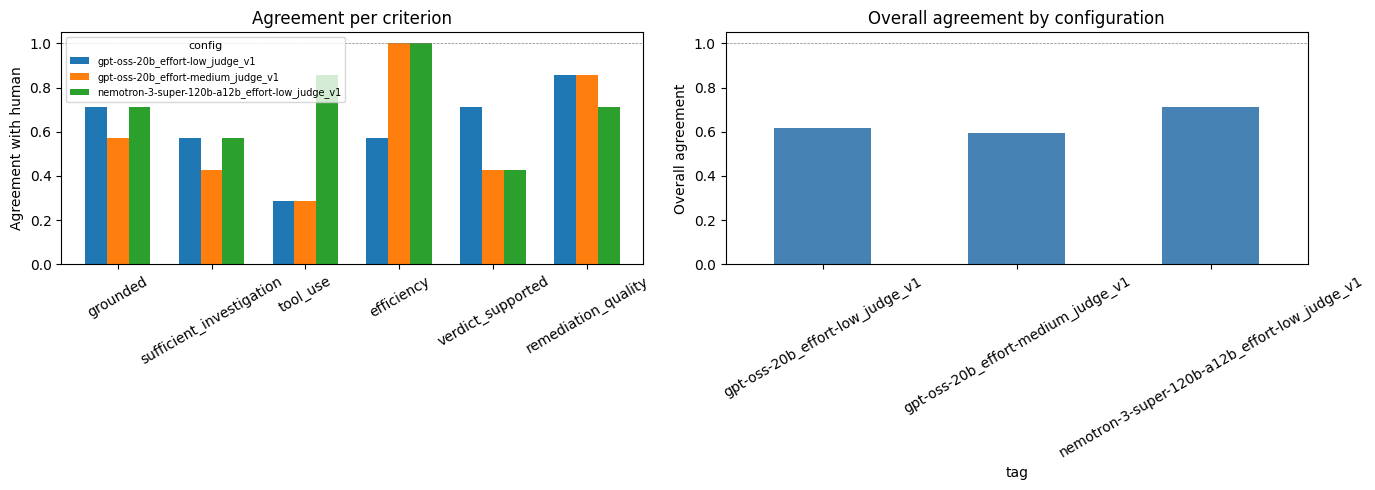

saved figure to labeling\judge_results/judge_calibration.png


In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# bar chart: agreement per criterion, grouped by config
criteria_cols = list(CRITERIA)
plot_data = summary[criteria_cols]
plot_data.T.plot.bar(ax=axes[0], rot=30, width=0.7)
axes[0].set_ylabel("Agreement with human")
axes[0].set_title("Agreement per criterion")
axes[0].set_ylim(0, 1.05)
axes[0].legend(title="config", fontsize=7, title_fontsize=8)
axes[0].axhline(y=1.0, color="grey", linestyle="--", linewidth=0.5)

# bar chart: overall agreement per config
summary["overall"].plot.bar(ax=axes[1], color="steelblue", rot=30)
axes[1].set_ylabel("Overall agreement")
axes[1].set_title("Overall agreement by configuration")
axes[1].set_ylim(0, 1.05)
axes[1].axhline(y=1.0, color="grey", linestyle="--", linewidth=0.5)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "judge_calibration.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"saved figure to {RESULTS_DIR.relative_to(ROOT)}/judge_calibration.png")

## Judge pass rates per criterion

One diagram per judge configuration showing the pass rate it gave on each criterion across all trajectories.

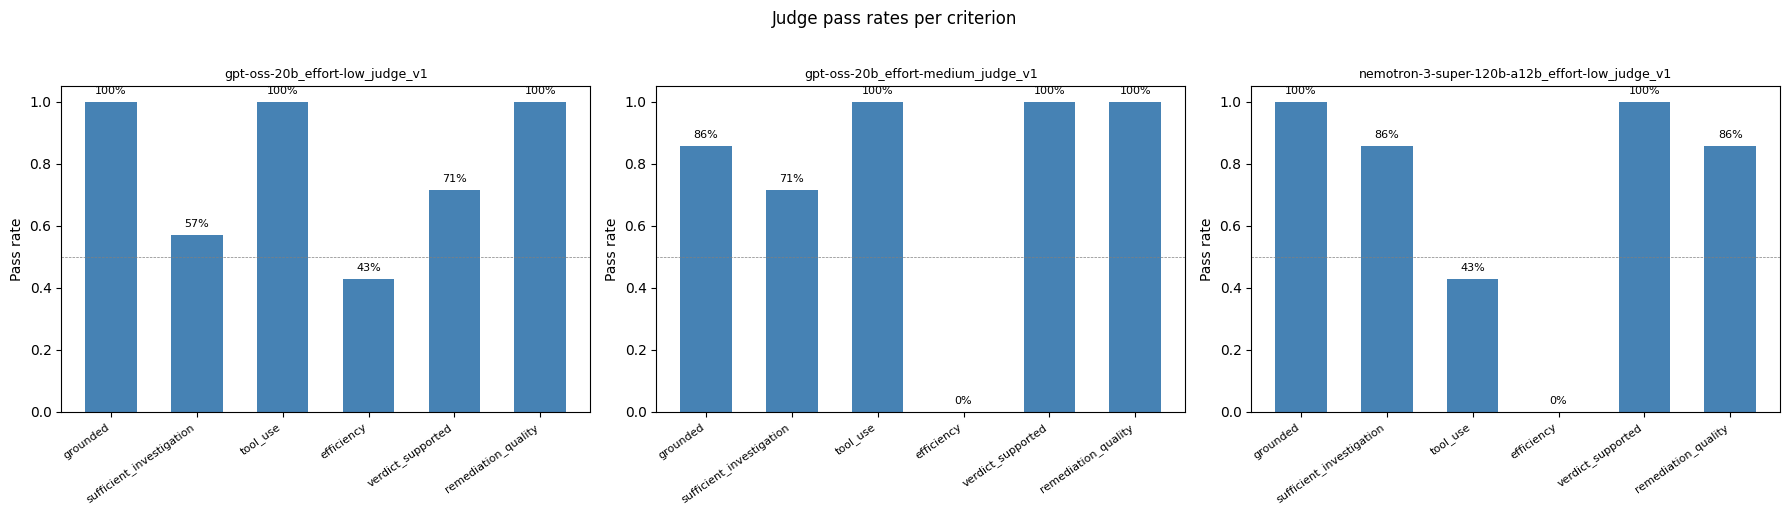

saved figure to labeling\judge_results/judge_pass_rates.png


In [8]:
import numpy as np

n_cfgs = len(JUDGE_CONFIGS)
fig, axes = plt.subplots(1, n_cfgs, figsize=(6 * n_cfgs, 5), squeeze=False)

for idx, cfg in enumerate(JUDGE_CONFIGS):
    ax = axes[0][idx]
    tag = cfg["tag"]

    # compute pass rate per criterion for this judge config
    pass_rates = []
    for c in CRITERIA:
        grades_for_c = [getattr(all_judgements[(r.traj_id, tag)], c).result for _, r in subset.iterrows()]
        pass_rates.append(sum(1 for g in grades_for_c if g == "pass") / len(grades_for_c))

    x = np.arange(len(CRITERIA))
    bars = ax.bar(x, pass_rates, color="steelblue", width=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(CRITERIA, rotation=35, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Pass rate")
    ax.set_title(tag, fontsize=9)
    ax.axhline(y=0.5, color="grey", linestyle="--", linewidth=0.5)

    for bar, rate in zip(bars, pass_rates):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02,
                f"{rate:.0%}", ha="center", va="bottom", fontsize=8)

plt.suptitle("Judge pass rates per criterion", fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "judge_pass_rates.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"saved figure to {RESULTS_DIR.relative_to(ROOT)}/judge_pass_rates.png")

## Disagreements per configuration
Read these to decide what to fix in the judge prompt.

In [9]:
for cfg in JUDGE_CONFIGS:
    tag = cfg["tag"]
    print(f"\n{'#' * 70}")
    print(f"# {tag}")
    print(f"{'#' * 70}")
    for c in CRITERIA:
        for _, r in subset.iterrows():
            j = all_judgements[(r.traj_id, tag)]
            human = r[c]
            grade = getattr(j, c)
            if human != grade.result:
                print(f"\n  {c}: {r.traj_id}")
                print(f"    human={human}  judge={grade.result}")
                print(f"    reasoning: {grade.reasoning}")


######################################################################
# gpt-oss-20b_effort-low_judge_v1
######################################################################

  grounded: c03__nemotron-3.5-lightning-30b-a3b_think200_8r
    human=fail  judge=pass
    reasoning: The verdict cites the new log line, the cluster-wide shape count, the gige3 timeline, and the what_followed summary. All of these are present in the starting context or in the tool results. No quoted line is missing or fabricated.

  grounded: c05__nemotron-3-super-120b-a12b_think200_4r
    human=fail  judge=pass
    reasoning: All facts in the verdict are directly taken from the starting context or the tool results. The new log line, the early log lines with ****, and the timeline showing only fan logs are all quoted and were present in the trajectory. No invented numbers or statements appear.

  sufficient_investigation: c01__nemotron-3-super-120b-a12b_think200_4r
    human=pass  judge=fail
    reasoning: The